# Ranked pathway components: reactions, metabolites and genes

One **megaquery** per scope (in [`sparql-examples-pmw`](https://github.com/pathway-lod/sparql-examples-pmw/tree/main/examples/MinimumInformationTiers)): `ranked-pathway-metabolites`, `ranked-pathway-reactions` and `ranked-pathway-genes`. Each lists the **pathway components** that reach at least one tier of evidence, with all the evidence as optional branches, and ranks them by a **score**.

**Score.** The evidence is grouped into *families* of tiers that are not independent of each other (for example EC and Rhea, all the annotation tools, or, for genes, the genes of a biosynthetic gene cluster and the genes of a pathway). A component takes the weight of the **strongest tier of each family**, and the score is the **noisy-OR over the families**:

$$\text{score} = 1 - \prod_{f} (1 - w_f)$$

The weights ([`weights.csv`](weights.csv)) are **drafts, to be calibrated** (see the last section). The notebook runs the three queries on the evidence graphs of the pilots (live on PlantMetWiki), explores the results and draws figures (saved in `figures/`). The outputs are a dated snapshot.

In [1]:
import mi
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option('display.max_colwidth', 70); pd.set_option('display.width', 200)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
INK, ACC = '#1f2933', '#3b82a6'
print('PlantMetWiki release:', mi.pmw_release())
w = pd.read_csv('weights.csv')
display(w)

PlantMetWiki release: r17.0.0_20260605-171052


,scope,family,tier,weight,in_live_megaquery,data_status,note
0,metabolite,identity,inchikey-exact,0.95,yes,data,full InChIKey incl. stereo/charge equal; multiplied by a support f...
1,metabolite,identity,inchikey-first-block,0.80,yes,data,first block (connectivity) equal; same support factor
2,metabolite,relatedness,shared-chemical-class,0.20,yes,no data yet,NPClassifier class shared with a pathway metabolite
3,metabolite,relatedness,similarity-link,0.40,yes,no data yet,0.40 x similarity score
4,metabolite,relatedness,structure-similarity,0.30,yes,data (about 10 min),same InChI formula layer (proxy)
5,metabolite,relatedness,idsm-similar-metabolites-in-pathway,0.50,yes,data (pathway PC968 only),IDSM/Sachem similarity to a substrate of a pathway; the component ...
6,metabolite,reaction,rhea-step-between-metabolites,0.70,no,too slow for the endpoint (60 s proxy limit),Rhea reaction connects two detected metabolites with a known enzyme
7,reaction,database identifiers,rhea,0.60,yes,data,Rhea identifier on the reaction
8,reaction,database identifiers,ec,0.40,yes,data,EC number on the reaction
9,reaction,enzyme,uniprot,0.70,yes,data,UniProt enzyme on the reaction


## Run the three megaqueries

In [2]:
runs = {
    'metabolite': mi.run('ranked-pathway-metabolites', ['annotation'], 'ranked', timeout=1200, max_rows=5000),
    'reaction': mi.run('ranked-pathway-reactions', ['association', 'annotation'], 'ranked', timeout=280, max_rows=20000),
    'gene': mi.run('ranked-pathway-genes', ['association', 'sample'], 'ranked', timeout=280, max_rows=5000),
}
for k, r in runs.items():
    mi.record(r)
    print(f"{k:11s} {r['status']:8s} {r['n_rows']} rows  {r['seconds']} s")
met, rea, gen = (runs[k]['table'].copy() for k in ('metabolite', 'reaction', 'gene'))
for d in (met, rea, gen):
    d['score'] = pd.to_numeric(d['score'])

metabolite  rows     3688 rows  620.9 s
reaction    rows     7772 rows  2.9 s
gene        rows     12 rows  126.7 s


## Metabolites

A component is a metabolite (first block of its InChIKey) in a pathway. The evidence that exists in the graphs today is the **annotation of detected metabolites** matching a PlantMetWiki metabolite (the weight grows with the number of annotation tools that agree), the **same InChI formula layer** as a pathway metabolite (a proxy for structure similarity, capped at 3,000 rows) and the **IDSM chemical similarity** to the substrates of one pathway (PC968, as the search runs once per metabolite). Classes and similarity links have no data yet, and the Rhea step between metabolites is not in the live query (see below). This query takes about 10 minutes, almost all of it in the formula-layer branch.

In [3]:
for c in ('supportingTools', 'supportingFeatures'): met[c] = pd.to_numeric(met[c])
print(len(met), 'metabolite-pathway pairs;', met['component'].nunique(), 'metabolites;', met['pathway'].nunique(), 'pathways')
display(met.head(12)[['component', 'pathway', 'score', 'tiersPassed', 'supportingTools', 'supportingFeatures']])

3688 metabolite-pathway pairs; 492 metabolites; 674 pathways


,component,pathway,score,tiersPassed,supportingTools,supportingFeatures
0,https://identifiers.org/inchikey/KRKNYBCHXYNGOX,PC571,0.965,"inchikey-exact, inchikey-first-block, structure-similarity",5,17
1,https://identifiers.org/inchikey/KRKNYBCHXYNGOX,PC461,0.965,"inchikey-exact, inchikey-first-block, structure-similarity",5,17
2,https://identifiers.org/inchikey/KRKNYBCHXYNGOX,PC1077,0.965,"inchikey-exact, inchikey-first-block, structure-similarity",5,17
3,https://identifiers.org/inchikey/KRKNYBCHXYNGOX,PC1119,0.965,"inchikey-exact, inchikey-first-block, structure-similarity",5,17
4,https://identifiers.org/inchikey/RODXRVNMMDRFIK,PC294,0.965,"inchikey-exact, inchikey-first-block, structure-similarity",5,18
5,https://identifiers.org/inchikey/CZMRCDWAGMRECN,PC497,0.965,"inchikey-exact, inchikey-first-block, structure-similarity",4,32
6,https://identifiers.org/inchikey/WQZGKKKJIJFFOK,PC1006,0.965,"inchikey-exact, inchikey-first-block, structure-similarity",4,19
7,https://identifiers.org/inchikey/FVXDQWZBHIXIEJ,PC410,0.965,"inchikey-exact, inchikey-first-block, structure-similarity",4,15
8,https://identifiers.org/inchikey/AYFVYJQAPQTCCC,PC500,0.965,"inchikey-exact, inchikey-first-block, structure-similarity",4,9
9,https://identifiers.org/inchikey/HXXFSFRBOHSIMQ,PC596,0.965,"inchikey-exact, inchikey-first-block, structure-similarity",4,4


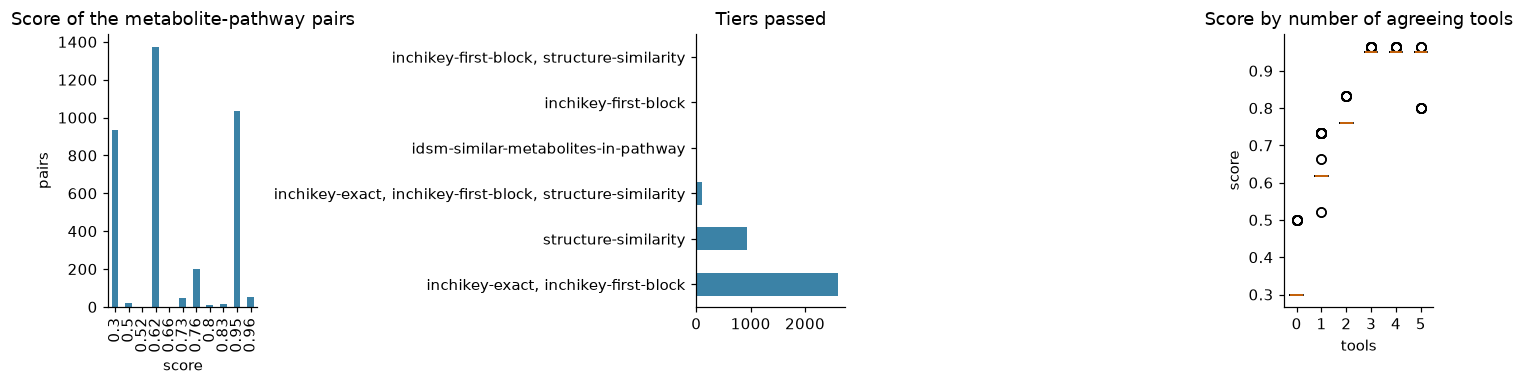

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
met['score'].round(2).value_counts().sort_index().plot.bar(ax=ax[0], color=ACC); ax[0].set_title('Score of the metabolite-pathway pairs'); ax[0].set_xlabel('score'); ax[0].set_ylabel('pairs')
met['tiersPassed'].value_counts().plot.barh(ax=ax[1], color=ACC); ax[1].set_title('Tiers passed'); ax[1].set_ylabel('')
ax[2].boxplot([met.loc[met['supportingTools'] == t, 'score'] for t in sorted(met['supportingTools'].unique())], tick_labels=sorted(met["supportingTools"].unique()))
ax[2].set_title('Score by number of agreeing tools'); ax[2].set_xlabel('tools'); ax[2].set_ylabel('score')
plt.tight_layout(); plt.savefig('figures/metabolites_scores.png', bbox_inches='tight'); plt.show()

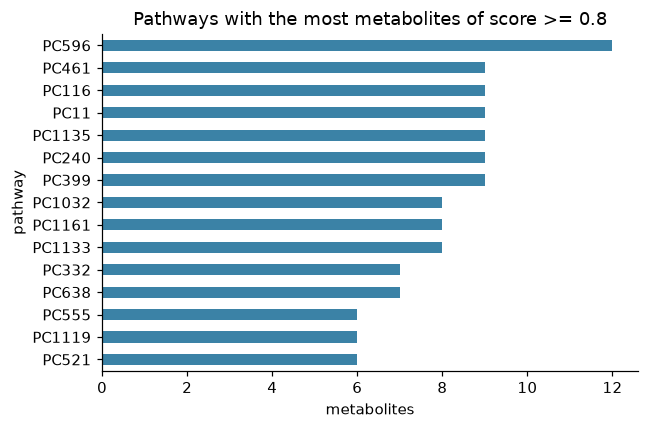

In [5]:
top = (met[met['score'] >= 0.8].groupby('pathway').size().sort_values(ascending=False).head(15))
ax = top.sort_values().plot.barh(color=ACC, figsize=(6, 4)); ax.set_title('Pathways with the most metabolites of score >= 0.8'); ax.set_xlabel('metabolites')
plt.tight_layout(); plt.savefig('figures/metabolites_top_pathways.png', bbox_inches='tight'); plt.show()

**For discussion:** is a full-InChIKey match (stereo and charge) really worth more than a connectivity match? How many agreeing tools should count as strong? Which pathways should be reviewed first?

*Comments:* 

## Reactions

A component is a PlantMetWiki reaction in a pathway. The evidence today is the **database evidence of PlantMetWiki** itself (Rhea and EC identifiers: one family; a UniProt enzyme on the reaction: another). The evidence that links reactions to our data (genes that catalyse a conversion between associated metabolites; machine-learning predicted reactions) has no data yet, so it does not change a score.

In [6]:
print(len(rea), 'reactions in', rea['pathway'].nunique(), 'pathways')
display(rea.head(8)[['component', 'pathway', 'score', 'tiersPassed', 'wDatabase', 'wEnzyme']])
rea['tiers'] = rea['tiersPassed'].fillna('').str.rstrip(';').replace('', 'none')

7772 reactions in 2476 pathways


,component,pathway,score,tiersPassed,wDatabase,wEnzyme
0,http://rdf-plantmetwiki.bioinformatics.nl/Pathway/PC544_r17.0.0_20...,PC544,0.88,ec;rhea;uniprot;,0.6,0.7
1,http://rdf-plantmetwiki.bioinformatics.nl/Pathway/PC152_r17.0.0_20...,PC152,0.88,rhea;uniprot;,0.6,0.7
2,http://rdf-plantmetwiki.bioinformatics.nl/Pathway/PC697_r17.0.0_20...,PC697,0.88,ec;rhea;uniprot;,0.6,0.7
3,http://rdf-plantmetwiki.bioinformatics.nl/Pathway/PC366_r17.0.0_20...,PC366,0.88,ec;rhea;uniprot;,0.6,0.7
4,http://rdf-plantmetwiki.bioinformatics.nl/Pathway/PC604_r17.0.0_20...,PC604,0.88,ec;rhea;uniprot;,0.6,0.7
5,http://rdf-plantmetwiki.bioinformatics.nl/Pathway/PC101_r17.0.0_20...,PC101,0.88,ec;rhea;uniprot;,0.6,0.7
6,http://rdf-plantmetwiki.bioinformatics.nl/Pathway/PC883_r17.0.0_20...,PC883,0.88,ec;rhea;uniprot;,0.6,0.7
7,http://rdf-plantmetwiki.bioinformatics.nl/Pathway/PC729_r17.0.0_20...,PC729,0.88,ec;rhea;uniprot;,0.6,0.7


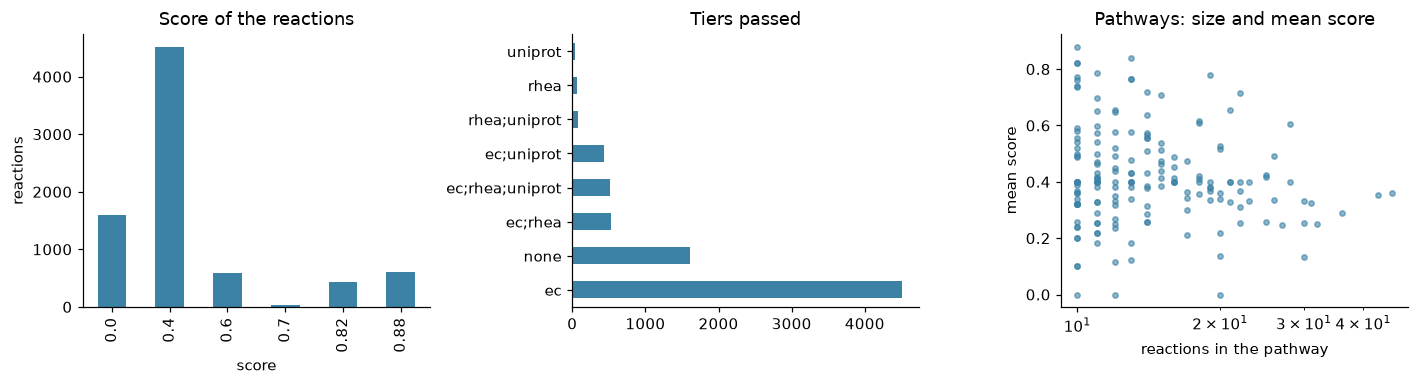

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
rea['score'].round(2).value_counts().sort_index().plot.bar(ax=ax[0], color=ACC); ax[0].set_title('Score of the reactions'); ax[0].set_xlabel('score'); ax[0].set_ylabel('reactions')
rea['tiers'].value_counts().plot.barh(ax=ax[1], color=ACC); ax[1].set_title('Tiers passed'); ax[1].set_ylabel('')
ratio = rea.groupby('pathway')['score'].agg(['mean', 'size']); ratio = ratio[ratio['size'] >= 10]
ax[2].scatter(ratio['size'], ratio['mean'], s=12, color=ACC, alpha=.6); ax[2].set_xscale('log'); ax[2].set_xlabel('reactions in the pathway'); ax[2].set_ylabel('mean score'); ax[2].set_title('Pathways: size and mean score')
plt.tight_layout(); plt.savefig('figures/reactions_scores.png', bbox_inches='tight'); plt.show()

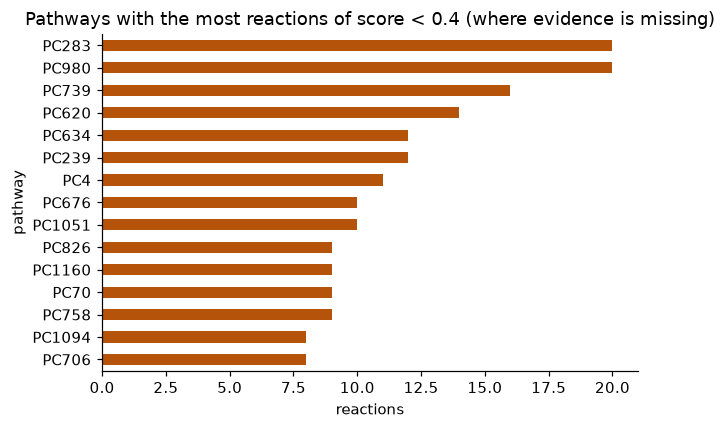

In [8]:
weak = (rea[rea['score'] < 0.4].groupby('pathway').size().sort_values(ascending=False).head(15))
ax = weak.sort_values().plot.barh(color='#b45309', figsize=(6, 4)); ax.set_title('Pathways with the most reactions of score < 0.4 (where evidence is missing)'); ax.set_xlabel('reactions')
plt.tight_layout(); plt.savefig('figures/reactions_weak_pathways.png', bbox_inches='tight'); plt.show()

**For discussion:** the reactions of PlantMetWiki are the curated base; the scores here describe how well each is annotated. Which of the 0-score reactions should be targets for new evidence from our pilots?

*Comments:* 

## Genes

A component is a gene (Solyc or Arabidopsis locus) in a pathway; the pathway is empty when a gene only has cluster evidence. The genes of a biosynthetic gene cluster and the genes of a pathway are **one family** (membership), co-expression another (omics), orthologs a third (sequence). Today the data are the sample graph (one *A. thaliana* cluster and one *S. lycopersicum* association) and the MEANtools associations, of which no gene is listed in PlantMetWiki by locus.

In [9]:
print(len(gen), 'gene rows')
display(gen[['component', 'pathway', 'score', 'tiersPassed', 'wMembership', 'wOmics', 'wSequence']])

12 gene rows


,component,pathway,score,tiersPassed,wMembership,wOmics,wSequence
0,https://identifiers.org/tair.name/AT5G48000,PC382,0.9,"bgc-both-in-pathway, gene-in-plantmetwiki-pathway, bgc-partner-in-...",0.9,0,0
1,https://identifiers.org/tair.name/AT5G47990,PC382,0.9,"bgc-both-in-pathway, gene-in-plantmetwiki-pathway, bgc-partner-in-...",0.9,0,0
2,https://plants.ensembl.org/Solanum_lycopersicum/Gene/Summary?g=Sol...,PC968,0.9,gene-in-plantmetwiki-pathway,0.9,0,0
3,https://identifiers.org/tair.name/AT5G48010,PC382,0.9,"bgc-both-in-pathway, gene-in-plantmetwiki-pathway, bgc-partner-in-...",0.9,0,0
4,https://plants.ensembl.org/Solanum_lycopersicum/Gene/Summary?g=Sol...,PC70,0.9,gene-in-plantmetwiki-pathway,0.9,0,0
5,https://identifiers.org/tair.name/AT5G47950,PC382,0.5,bgc-partner-in-pathway,0.5,0,0
6,https://identifiers.org/tair.name/AT5G47980,PC382,0.5,bgc-partner-in-pathway,0.5,0,0
7,https://identifiers.org/tair.name/AT5G48010,NaN,0.3,genes-in-same-bgc,0.3,0,0
8,https://identifiers.org/tair.name/AT5G47990,NaN,0.3,genes-in-same-bgc,0.3,0,0
9,https://identifiers.org/tair.name/AT5G48000,NaN,0.3,genes-in-same-bgc,0.3,0,0


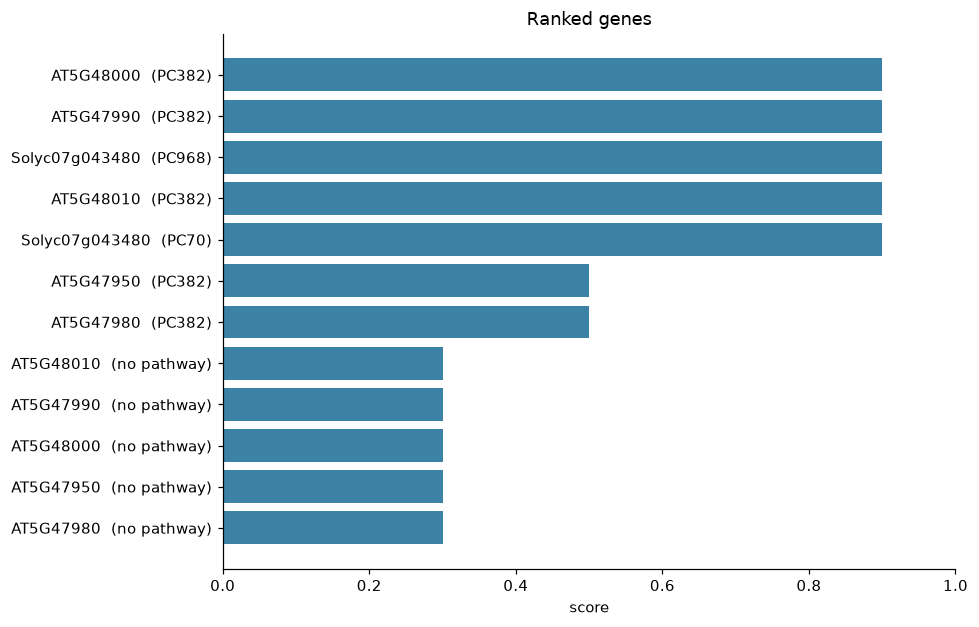

In [10]:
if len(gen):
    fig, ax = plt.subplots(figsize=(9, 0.4 * len(gen) + 1))
    lab = [f"{c.split('/')[-1].split('=')[-1]}  ({p if isinstance(p, str) else 'no pathway'})" for c, p in zip(gen['component'], gen['pathway'])]
    ax.barh(lab[::-1], gen['score'][::-1], color=ACC); ax.set_xlim(0, 1); ax.set_xlabel('score'); ax.set_title('Ranked genes')
    plt.tight_layout(); plt.savefig('figures/genes_ranked.png', bbox_inches='tight'); plt.show()

**For discussion:** a gene that is already listed in the pathway gets no extra credit from a cluster that also lies in it (the evidence is not independent). Do we agree? What data would let the cluster and co-expression tiers separate genes that are new candidates?

*Comments:* 

## How many components pass which level (all scopes)

,metabolites,reactions,genes
score >= 0.3,3688,6167,12
score >= 0.5,2754,1654,7
score >= 0.7,1359,1062,5
score >= 0.9,1089,0,5


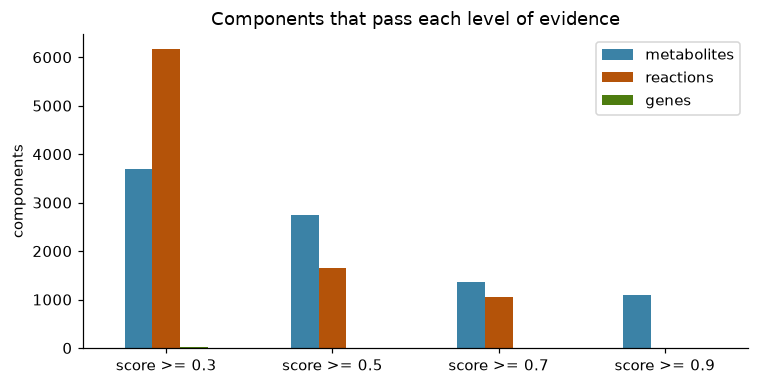

In [11]:
levels = [0.3, 0.5, 0.7, 0.9]
funnel = pd.DataFrame({k: [int((d['score'] >= t).sum()) for t in levels] for k, d in (('metabolites', met), ('reactions', rea), ('genes', gen))}, index=[f'score >= {t}' for t in levels])
display(funnel)
ax = funnel.plot.bar(figsize=(7, 3.6), color=[ACC, '#b45309', '#4d7c0f']); ax.set_ylabel('components'); ax.set_title('Components that pass each level of evidence'); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig('figures/funnel.png', bbox_inches='tight'); plt.show()

## Sensitivity of the ranking to the weights

The weights are drafts. This shows how much the ranking changes when the weight of each family is changed at random by up to 20% (200 draws), using the family weights returned by the query. A ranking that hardly changes is not sensitive to the exact weights.

In [12]:
rng = np.random.default_rng(0)
def noisy_or(df, cols, factors):
    p = np.ones(len(df))
    for c, f in zip(cols, factors):
        p *= 1 - np.clip(pd.to_numeric(df[c]).fillna(0).to_numpy() * f, 0, 1)
    return 1 - p
rows = []
for name, df, cols in (('metabolites', met, ['wIdentity', 'wRelatedness', 'wReaction']), ('reactions', rea, ['wDatabase', 'wEnzyme', 'wOmics', 'wPrediction']), ('genes', gen, ['wMembership', 'wOmics', 'wSequence'])):
    if len(df) < 5: continue
    cols = [c for c in cols if c in df.columns]
    base = noisy_or(df, cols, [1] * len(cols))
    rho, overlap = [], []
    k = max(1, len(df) // 10)
    top0 = set(np.argsort(-base, kind='stable')[:k])
    for _ in range(200):
        s = noisy_or(df, cols, rng.uniform(0.8, 1.2, len(cols)))
        rho.append(pd.Series(base).rank().corr(pd.Series(s).rank()))
        overlap.append(len(top0 & set(np.argsort(-s, kind='stable')[:k])) / k)
    rows.append((name, len(df), round(float(np.mean(rho)), 3), round(float(np.mean(overlap)), 3)))
display(pd.DataFrame(rows, columns=['scope', 'components', 'mean rank correlation', 'mean overlap of the top 10%']))

,scope,components,mean rank correlation,mean overlap of the top 10%
0,metabolites,3688,0.999,1.0
1,reactions,7772,1.000,1.0
2,genes,12,1.000,1.0


## Next: calibrate and test the weights

1. **Hold-out test:** hide a curated PlantMetWiki pathway (or the reactions of a species), run the tiers and measure the share of the hidden components that each tier recovers. That share is an estimate of the precision of the tier and can replace the draft weights.
2. **Null model:** shuffle the associations and annotations to see how many components reach a tier by chance (the ipecac data showed that some correlations are at chance level).
3. **Positive control:** the ipecac pathway has experimental evidence for its reactions and genes; the highest tiers should find it.
4. **Curator review** of the top components per scope, from this notebook.